# S10 - Series de tiempo e inferencia en streaming

## Proyecto: Predicción del precio de Bitcoin BTC/USDT

**Estudiante:** Julmer Quispe Apaza

### Objetivo

Construir un modelo de series de tiempo para predecir el precio de cierre de Bitcoin (BTC/USDT) del siguiente intervalo temporal utilizando Apache Spark.

Se comparará un baseline de persistencia contra modelos de Machine Learning, utilizando Linear Regression y Random Forest Regressor.

Los modelos serán evaluados mediante RMSE, MAE y R².

Finalmente, el modelo seleccionado será guardado mediante PipelineModel y aplicado sobre eventos recibidos en tiempo real mediante Apache Kafka y Spark Structured Streaming.
    

In [1]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("S10-Crypto-BTC-Series-Tiempo")
    .master("local[*]")
    .config(
        "spark.jars.packages",
        "org.apache.spark:spark-sql-kafka-0-10_2.13:4.2.0"
    )
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("WARN")

spark

:: loading settings :: url = jar:file:/usr/local/lib/python3.10/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /root/.ivy2.5.2/cache
The jars for the packages stored in: /root/.ivy2.5.2/jars
org.apache.spark#spark-sql-kafka-0-10_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-068af4d2-a219-49c6-8805-c1659a9ab714;1.0
	confs: [default]
	found org.apache.spark#spark-sql-kafka-0-10_2.13;4.2.0 in central
	found org.apache.spark#spark-token-provider-kafka-0-10_2.13;4.2.0 in central
	found org.apache.kafka#kafka-clients;3.9.2 in central
	found at.yawk.lz4#lz4-java;1.11.0 in central
	found org.xerial.snappy#snappy-java;1.1.10.8 in central
	found org.slf4j#slf4j-api;2.0.17 in central
	found org.apache.hadoop#hadoop-client-runtime;3.5.0 in central
	found org.apache.hadoop#hadoop-client-api;3.5.0 in central
	found com.google.code.findbugs#jsr305;3.0.0 in central
	found org.scala-lang.mod

## Fase 2 — Data Understanding

Se utilizarán datos históricos reales de Bitcoin (BTC/USDT)
correspondientes al año 2024, con una frecuencia de una observación
por minuto.

La fuente contiene información OHLCV y datos adicionales de actividad
del mercado. Los archivos mensuales serán procesados conjuntamente
mediante Apache Spark.

In [5]:
RUTA_CRYPTO = "./data/crypto/raw/*.csv"

In [6]:
import glob

RUTA_CRYPTO = "./data/crypto/raw/*.csv"

archivos = glob.glob(RUTA_CRYPTO)

print("Ruta utilizada:", RUTA_CRYPTO)
print("Cantidad de archivos encontrados:", len(archivos))

for archivo in archivos[:5]:
    print(archivo)

Ruta utilizada: ./data/crypto/raw/*.csv
Cantidad de archivos encontrados: 12
./data/crypto/raw/BTCUSDT-1m-2024-01.csv
./data/crypto/raw/BTCUSDT-1m-2024-02.csv
./data/crypto/raw/BTCUSDT-1m-2024-03.csv
./data/crypto/raw/BTCUSDT-1m-2024-04.csv
./data/crypto/raw/BTCUSDT-1m-2024-05.csv


In [7]:
from pyspark.sql.types import (
    StructType,
    StructField,
    LongType,
    DoubleType
)

esquema_crypto = StructType([
    StructField("open_time", LongType(), True),
    StructField("open", DoubleType(), True),
    StructField("high", DoubleType(), True),
    StructField("low", DoubleType(), True),
    StructField("close", DoubleType(), True),
    StructField("volume", DoubleType(), True),
    StructField("close_time", LongType(), True),
    StructField("quote_volume", DoubleType(), True),
    StructField("trades", LongType(), True),
    StructField("taker_buy_volume", DoubleType(), True),
    StructField("taker_buy_quote_volume", DoubleType(), True),
    StructField("ignore", DoubleType(), True)
])

In [8]:
df_raw = (
    spark.read
    .option("header", "false")
    .schema(esquema_crypto)
    .csv(RUTA_CRYPTO)
)

print("Archivos BTC cargados correctamente")

26/10/21 15:37:38 WARN FileStreamSink: Assume no metadata directory. Error while looking for metadata directory in the path: ./data/crypto/raw/*.csv.
java.io.FileNotFoundException: File data/crypto/raw/*.csv does not exist
	at org.apache.hadoop.fs.RawLocalFileSystem.deprecatedGetFileStatus(RawLocalFileSystem.java:980)
	at org.apache.hadoop.fs.RawLocalFileSystem.getFileLinkStatusInternal(RawLocalFileSystem.java:1301)
	at org.apache.hadoop.fs.RawLocalFileSystem.getFileStatus(RawLocalFileSystem.java:970)
	at org.apache.hadoop.fs.FilterFileSystem.getFileStatus(FilterFileSystem.java:462)
	at org.apache.spark.sql.execution.streaming.sinks.FileStreamSink$.hasMetadata(FileStreamSink.scala:58)
	at org.apache.spark.sql.execution.datasources.DataSource.resolveRelation(DataSource.scala:394)
	at org.apache.spark.sql.catalyst.analysis.ResolveDataSource.org$apache$spark$sql$catalyst$analysis$ResolveDataSource$$loadV1BatchSource(ResolveDataSource.scala:210)
	at org.apache.spark.sql.catalyst.analysis.R

Archivos BTC cargados correctamente


In [10]:
df_raw.printSchema()

root
 |-- open_time: long (nullable = true)
 |-- open: double (nullable = true)
 |-- high: double (nullable = true)
 |-- low: double (nullable = true)
 |-- close: double (nullable = true)
 |-- volume: double (nullable = true)
 |-- close_time: long (nullable = true)
 |-- quote_volume: double (nullable = true)
 |-- trades: long (nullable = true)
 |-- taker_buy_volume: double (nullable = true)
 |-- taker_buy_quote_volume: double (nullable = true)
 |-- ignore: double (nullable = true)



In [11]:
df_raw.show(10, truncate=False)

+-------------+--------+--------+--------+--------+--------+-------------+---------------+------+----------------+----------------------+------+
|open_time    |open    |high    |low     |close   |volume  |close_time   |quote_volume   |trades|taker_buy_volume|taker_buy_quote_volume|ignore|
+-------------+--------+--------+--------+--------+--------+-------------+---------------+------+----------------+----------------------+------+
|1733011200000|96407.99|96411.99|96376.0 |96376.0 |8.18452 |1733011259999|788996.1628126 |1763  |3.18577         |307128.8909746        |0.0   |
|1733011260000|96376.0 |96384.76|96350.13|96350.13|6.72047 |1733011319999|647671.0362169 |1652  |1.79784         |173254.1385468        |0.0   |
|1733011320000|96350.13|96411.99|96350.13|96411.99|3.50598 |1733011379999|337868.2644378 |2116  |2.7428          |264314.4741611        |0.0   |
|1733011380000|96411.99|96491.58|96408.01|96491.58|5.55435 |1733011439999|535661.3949977 |2599  |4.00182         |385967.4814848  

In [13]:
total_registros = df_raw.count()

print(f"Total de registros BTC/USDT: {total_registros:,}")

Total de registros BTC/USDT: 527,040


In [14]:
from pyspark.sql import functions as F

df_crypto = (
    df_raw
    .withColumn(
        "timestamp",
        (F.col("open_time") / 1000).cast("timestamp")
    )
    .select(
        "timestamp",
        "open",
        "high",
        "low",
        "close",
        "volume",
        "quote_volume",
        "trades",
        "taker_buy_volume"
    )
)

In [15]:
df_crypto.show(10, truncate=False)

+-------------------+--------+--------+--------+--------+--------+---------------+------+----------------+
|timestamp          |open    |high    |low     |close   |volume  |quote_volume   |trades|taker_buy_volume|
+-------------------+--------+--------+--------+--------+--------+---------------+------+----------------+
|2024-12-01 00:00:00|96407.99|96411.99|96376.0 |96376.0 |8.18452 |788996.1628126 |1763  |3.18577         |
|2024-12-01 00:01:00|96376.0 |96384.76|96350.13|96350.13|6.72047 |647671.0362169 |1652  |1.79784         |
|2024-12-01 00:02:00|96350.13|96411.99|96350.13|96411.99|3.50598 |337868.2644378 |2116  |2.7428          |
|2024-12-01 00:03:00|96411.99|96491.58|96408.01|96491.58|5.55435 |535661.3949977 |2599  |4.00182         |
|2024-12-01 00:04:00|96491.57|96524.0 |96491.57|96508.29|11.91174|1149563.5410729|2103  |7.28669         |
|2024-12-01 00:05:00|96508.29|96526.0 |96488.01|96497.67|5.28992 |510544.026301  |2479  |1.83898         |
|2024-12-01 00:06:00|96497.67|96512.2

In [16]:
df_crypto.select(
    F.min("timestamp").alias("fecha_inicio"),
    F.max("timestamp").alias("fecha_fin")
).show(truncate=False)

+-------------------+-------------------+
|fecha_inicio       |fecha_fin          |
+-------------------+-------------------+
|2024-01-01 00:00:00|2024-12-31 23:59:00|
+-------------------+-------------------+



In [17]:
df_crypto.show(10, truncate=False)

+-------------------+--------+--------+--------+--------+--------+---------------+------+----------------+
|timestamp          |open    |high    |low     |close   |volume  |quote_volume   |trades|taker_buy_volume|
+-------------------+--------+--------+--------+--------+--------+---------------+------+----------------+
|2024-12-01 00:00:00|96407.99|96411.99|96376.0 |96376.0 |8.18452 |788996.1628126 |1763  |3.18577         |
|2024-12-01 00:01:00|96376.0 |96384.76|96350.13|96350.13|6.72047 |647671.0362169 |1652  |1.79784         |
|2024-12-01 00:02:00|96350.13|96411.99|96350.13|96411.99|3.50598 |337868.2644378 |2116  |2.7428          |
|2024-12-01 00:03:00|96411.99|96491.58|96408.01|96491.58|5.55435 |535661.3949977 |2599  |4.00182         |
|2024-12-01 00:04:00|96491.57|96524.0 |96491.57|96508.29|11.91174|1149563.5410729|2103  |7.28669         |
|2024-12-01 00:05:00|96508.29|96526.0 |96488.01|96497.67|5.28992 |510544.026301  |2479  |1.83898         |
|2024-12-01 00:06:00|96497.67|96512.2

In [18]:
print(f"Total de registros BTC/USDT: {total_registros:,}")

Total de registros BTC/USDT: 527,040


In [19]:
df_crypto.select(
    F.min("timestamp").alias("fecha_inicio"),
    F.max("timestamp").alias("fecha_fin")
).show(truncate=False)

+-------------------+-------------------+
|fecha_inicio       |fecha_fin          |
+-------------------+-------------------+
|2024-01-01 00:00:00|2024-12-31 23:59:00|
+-------------------+-------------------+



In [20]:
df_crypto.orderBy("timestamp").show(10, truncate=False)

+-------------------+--------+--------+--------+--------+--------+---------------+------+----------------+
|timestamp          |open    |high    |low     |close   |volume  |quote_volume   |trades|taker_buy_volume|
+-------------------+--------+--------+--------+--------+--------+---------------+------+----------------+
|2024-01-01 00:00:00|42283.58|42298.62|42261.02|42298.61|35.92724|1519031.6945192|1327  |23.18766        |
|2024-01-01 00:01:00|42298.62|42320.0 |42298.61|42320.0 |21.16779|895580.8610456 |1348  |13.47483        |
|2024-01-01 00:02:00|42319.99|42331.54|42319.99|42325.5 |21.60391|914371.1381861 |1019  |11.21801        |
|2024-01-01 00:03:00|42325.5 |42368.0 |42325.49|42367.99|30.5073 |1291996.9465156|1241  |24.04878        |
|2024-01-01 00:04:00|42368.0 |42397.23|42367.99|42397.23|46.05107|1951945.1923031|1415  |34.12804        |
|2024-01-01 00:05:00|42397.22|42409.2 |42385.26|42409.2 |32.26766|1368040.0098892|1255  |20.99093        |
|2024-01-01 00:06:00|42409.19|42431.0

In [21]:
df_crypto.orderBy(F.desc("timestamp")).show(10, truncate=False)

+-------------------+--------+--------+--------+--------+-------+--------------+------+----------------+
|timestamp          |open    |high    |low     |close   |volume |quote_volume  |trades|taker_buy_volume|
+-------------------+--------+--------+--------+--------+-------+--------------+------+----------------+
|2024-12-31 23:59:00|93600.01|93616.05|93576.0 |93576.0 |5.48662|513548.2642572|1062  |3.26948         |
|2024-12-31 23:58:00|93616.05|93616.05|93600.0 |93600.0 |2.17256|203385.127592 |441   |1.09126         |
|2024-12-31 23:57:00|93636.38|93643.24|93616.04|93616.04|2.1923 |205276.7809361|698   |0.88765         |
|2024-12-31 23:56:00|93667.51|93676.98|93636.37|93636.37|2.87066|268877.5298399|1155  |1.15857         |
|2024-12-31 23:55:00|93646.97|93667.52|93646.96|93667.52|4.31339|403978.4449641|452   |3.97547         |
|2024-12-31 23:54:00|93669.99|93669.99|93646.96|93646.96|2.23049|208916.7354434|660   |0.36087         |
|2024-12-31 23:53:00|93687.37|93702.15|93669.98|93669.9

In [22]:
columnas = df_crypto.columns

df_crypto.select([
    F.sum(F.col(c).isNull().cast("int")).alias(c)
    for c in columnas
]).show(truncate=False)

+---------+----+----+---+-----+------+------------+------+----------------+
|timestamp|open|high|low|close|volume|quote_volume|trades|taker_buy_volume|
+---------+----+----+---+-----+------+------------+------+----------------+
|0        |0   |0   |0  |0    |0     |0           |0     |0               |
+---------+----+----+---+-----+------+------------+------+----------------+



In [23]:
duplicados = (
    df_crypto
    .groupBy("timestamp")
    .count()
    .filter(F.col("count") > 1)
)

print("Timestamps duplicados:", duplicados.count())

[Stage 20:>                                                       (0 + 12) / 12]

Timestamps duplicados: 0


In [24]:
df_crypto.select(
    "open",
    "high",
    "low",
    "close",
    "volume",
    "quote_volume",
    "trades",
    "taker_buy_volume"
).describe().show(truncate=False)

26/10/21 15:40:44 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+-------+-----------------+------------------+------------------+------------------+------------------+-------------------+------------------+------------------+
|summary|open             |high              |low               |close             |volume            |quote_volume       |trades            |taker_buy_volume  |
+-------+-----------------+------------------+------------------+------------------+------------------+-------------------+------------------+------------------+
|count  |527040           |527040            |527040            |527040            |527040            |527040             |527040            |527040            |
|mean   |65896.04565678125|65920.64251166987 |65871.10500199131 |65896.14200286582 |24.535352476777874|1612297.7315872377 |1926.1555232999392|12.18552560375494 |
|stddev |14679.79712490767|14686.199067859421|14673.373198407264|14679.810827885665|39.49929043245106 |2635861.7302612937 |2524.3998804456805|21.276420904836698|
|min    |38558.92         |3

## Fase 3 — Data Preparation

Para convertir los datos históricos de Bitcoin en un problema supervisado
de series de tiempo, se utilizará el precio de cierre (`close`) del siguiente
minuto como variable objetivo.

El dataset será ordenado cronológicamente mediante `timestamp` y se
construirá `label` utilizando `lead(close, 1)`.

De esta forma:

- `close_t` representa el precio actual.
- `label` representa el precio de cierre del minuto siguiente (`close_t+1`).

Posteriormente, el dataset será dividido cronológicamente en 80 % para
entrenamiento y 20 % para prueba, evitando fuga de información temporal.

In [25]:
VARIABLES_CRYPTO = [
    "close",
    "open",
    "high",
    "low",
    "volume",
    "quote_volume",
    "trades",
    "taker_buy_volume"
]

print("Variables predictoras:")
for variable in VARIABLES_CRYPTO:
    print("-", variable)

Variables predictoras:
- close
- open
- high
- low
- volume
- quote_volume
- trades
- taker_buy_volume


In [27]:
from pyspark.sql.window import Window

orden_temporal = Window.orderBy("timestamp")

dataset_ml = (
    df_crypto
    .withColumn(
        "label",
        F.lead("close", 1).over(orden_temporal)
    )
    .select(
        "timestamp",
        *VARIABLES_CRYPTO,
        "label"
    )
    .na.drop()
)

In [28]:
dataset_ml.orderBy("timestamp").select(
    "timestamp",
    "close",
    "label"
).show(20, truncate=False)

26/10/21 15:42:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:42:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:42:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:42:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:42:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


+-------------------+--------+--------+
|timestamp          |close   |label   |
+-------------------+--------+--------+
|2024-01-01 00:00:00|42298.61|42320.0 |
|2024-01-01 00:01:00|42320.0 |42325.5 |
|2024-01-01 00:02:00|42325.5 |42367.99|
|2024-01-01 00:03:00|42367.99|42397.23|
|2024-01-01 00:04:00|42397.23|42409.2 |
|2024-01-01 00:05:00|42409.2 |42423.95|
|2024-01-01 00:06:00|42423.95|42414.45|
|2024-01-01 00:07:00|42414.45|42420.07|
|2024-01-01 00:08:00|42420.07|42409.96|
|2024-01-01 00:09:00|42409.96|42440.05|
|2024-01-01 00:10:00|42440.05|42479.32|
|2024-01-01 00:11:00|42479.32|42462.24|
|2024-01-01 00:12:00|42462.24|42480.15|
|2024-01-01 00:13:00|42480.15|42488.0 |
|2024-01-01 00:14:00|42488.0 |42510.0 |
|2024-01-01 00:15:00|42510.0 |42541.27|
|2024-01-01 00:16:00|42541.27|42503.36|
|2024-01-01 00:17:00|42503.36|42474.03|
|2024-01-01 00:18:00|42474.03|42458.85|
|2024-01-01 00:19:00|42458.85|42459.31|
+-------------------+--------+--------+
only showing top 20 rows


In [29]:
total_supervisado = dataset_ml.count()

print(f"Dataset original: {total_registros:,}")
print(f"Dataset supervisado: {total_supervisado:,}")
print(f"Filas eliminadas: {total_registros - total_supervisado:,}")

26/10/21 15:42:42 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:42:42 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:42:42 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:42:42 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


Dataset original: 527,040
Dataset supervisado: 527,039
Filas eliminadas: 1


In [ ]:
randomSplit()

In [31]:
numerado = dataset_ml.withColumn(
    "numeroFila",
    F.row_number().over(orden_temporal)
)

total_filas = numerado.count()

corte = int(total_filas * 0.80)

print("Total:", total_filas)
print("Punto de corte:", corte)

26/10/21 15:42:58 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:42:58 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:42:58 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:42:58 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


Total: 527039
Punto de corte: 421631


In [34]:
train = (
    numerado
    .filter(F.col("numeroFila") <= corte)
    .drop("numeroFila")
)

test = (
    numerado
    .filter(F.col("numeroFila") > corte)
    .drop("numeroFila")
)

In [35]:
print(f"Entrenamiento: {train.count():,}")
print(f"Prueba: {test.count():,}")

26/10/21 15:43:51 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:43:51 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:43:51 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:43:51 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:43:51 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:43:51 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 1

Entrenamiento: 421,631


26/10/21 15:43:51 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:43:51 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:43:51 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:43:51 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:43:52 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:43:52 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 1

Prueba: 105,408


In [36]:
fecha_max_train = train.agg(
    F.max("timestamp")
).first()[0]

fecha_min_test = test.agg(
    F.min("timestamp")
).first()[0]

print("Último registro de entrenamiento:", fecha_max_train)
print("Primer registro de prueba:", fecha_min_test)

if fecha_max_train >= fecha_min_test:
    raise ValueError(
        "ERROR: existe fuga de información temporal."
    )

print("✓ División cronológica correcta")
print("✓ No existe fuga temporal entre train y test")

26/10/21 15:43:57 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:43:57 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:43:57 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:43:57 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:43:57 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:43:57 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 1

Último registro de entrenamiento: 2024-10-19 19:10:00
Primer registro de prueba: 2024-10-19 19:11:00
✓ División cronológica correcta
✓ No existe fuga temporal entre train y test


## Fase 4 — Modeling

### Baseline de persistencia

Antes de entrenar modelos de Machine Learning se calculará un baseline
de persistencia.

En este caso, el baseline asume que el precio de cierre de Bitcoin del
siguiente minuto será igual al precio de cierre del minuto actual.

Por tanto:

`close_t+1 = close_t`

Este resultado servirá como referencia para determinar si los modelos
de Machine Learning realmente aportan una mejora.

In [37]:
from pyspark.ml.evaluation import RegressionEvaluator

evaluador_rmse = RegressionEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="rmse"
)

evaluador_mae = RegressionEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="mae"
)

evaluador_r2 = RegressionEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="r2"
)

In [38]:
def evaluar(predicciones, nombre):

    resultado = {
        "Modelo": nombre,
        "RMSE": evaluador_rmse.evaluate(predicciones),
        "MAE": evaluador_mae.evaluate(predicciones),
        "R2": evaluador_r2.evaluate(predicciones)
    }

    print(f"Modelo: {nombre}")
    print(f"RMSE: {resultado['RMSE']:.6f}")
    print(f"MAE : {resultado['MAE']:.6f}")
    print(f"R²  : {resultado['R2']:.6f}")

    return resultado

In [39]:
test_persistencia = test.withColumn(
    "prediction",
    F.col("close")
)

In [40]:
resultado_persistencia = evaluar(
    test_persistencia,
    "Persistencia BTC"
)

26/10/21 15:46:31 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:46:31 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:46:31 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:46:31 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:46:31 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:46:32 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 1

Modelo: Persistencia BTC
RMSE: 66.298128
MAE : 43.681872
R²  : 0.999972


In [41]:
test_persistencia.select(
    "timestamp",
    "close",
    "label",
    "prediction"
).orderBy("timestamp").show(15, truncate=False)

26/10/21 15:46:41 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:46:41 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:46:41 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:46:41 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:46:41 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:46:41 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 1

+-------------------+--------+--------+----------+
|timestamp          |close   |label   |prediction|
+-------------------+--------+--------+----------+
|2024-10-19 19:11:00|68179.99|68185.99|68179.99  |
|2024-10-19 19:12:00|68185.99|68185.99|68185.99  |
|2024-10-19 19:13:00|68185.99|68188.0 |68185.99  |
|2024-10-19 19:14:00|68188.0 |68188.0 |68188.0   |
|2024-10-19 19:15:00|68188.0 |68187.99|68188.0   |
|2024-10-19 19:16:00|68187.99|68188.19|68187.99  |
|2024-10-19 19:17:00|68188.19|68188.19|68188.19  |
|2024-10-19 19:18:00|68188.19|68188.18|68188.19  |
|2024-10-19 19:19:00|68188.18|68188.19|68188.18  |
|2024-10-19 19:20:00|68188.19|68188.19|68188.19  |
|2024-10-19 19:21:00|68188.19|68203.51|68188.19  |
|2024-10-19 19:22:00|68203.51|68214.0 |68203.51  |
|2024-10-19 19:23:00|68214.0 |68215.4 |68214.0   |
|2024-10-19 19:24:00|68215.4 |68215.41|68215.4   |
|2024-10-19 19:25:00|68215.41|68242.42|68215.41  |
+-------------------+--------+--------+----------+
only showing top 15 rows


In [42]:
resultado_persistencia

{'Modelo': 'Persistencia BTC',
 'RMSE': 66.29812821550185,
 'MAE': 43.68187224878586,
 'R2': 0.9999723464011598}

### Modelo 1 — Linear Regression

Se entrenará un modelo de Regresión Lineal utilizando las variables
actuales del mercado de Bitcoin para predecir el precio de cierre
del siguiente minuto.

Las variables predictoras utilizadas son:

- close
- open
- high
- low
- volume
- quote_volume
- trades
- taker_buy_volume

In [43]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression

assembler = VectorAssembler(
    inputCols=VARIABLES_CRYPTO,
    outputCol="features"
)

train_ml = assembler.transform(train)
test_ml = assembler.transform(test)

In [44]:
train_ml.select(
    "timestamp",
    "close",
    "label",
    "features"
).show(5, truncate=False)

26/10/21 15:48:34 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:48:34 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:48:34 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:48:34 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:48:34 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:48:35 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 1

+-------------------+--------+--------+------------------------------------------------------------------------------+
|timestamp          |close   |label   |features                                                                      |
+-------------------+--------+--------+------------------------------------------------------------------------------+
|2024-01-01 00:00:00|42298.61|42320.0 |[42298.61,42283.58,42298.62,42261.02,35.92724,1519031.6945192,1327.0,23.18766]|
|2024-01-01 00:01:00|42320.0 |42325.5 |[42320.0,42298.62,42320.0,42298.61,21.16779,895580.8610456,1348.0,13.47483]   |
|2024-01-01 00:02:00|42325.5 |42367.99|[42325.5,42319.99,42331.54,42319.99,21.60391,914371.1381861,1019.0,11.21801]  |
|2024-01-01 00:03:00|42367.99|42397.23|[42367.99,42325.5,42368.0,42325.49,30.5073,1291996.9465156,1241.0,24.04878]   |
|2024-01-01 00:04:00|42397.23|42409.2 |[42397.23,42368.0,42397.23,42367.99,46.05107,1951945.1923031,1415.0,34.12804] |
+-------------------+--------+--------+---------

In [45]:
lr = LinearRegression(
    featuresCol="features",
    labelCol="label"
)

modelo_lr = lr.fit(train_ml)

26/10/21 15:48:41 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:48:41 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:48:41 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:48:41 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:48:41 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:48:43 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 1

In [46]:
lr = LinearRegression(
    featuresCol="features",
    labelCol="label"
)

modelo_lr = lr.fit(train_ml)

26/10/21 15:49:12 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:49:12 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:49:12 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:49:12 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:49:12 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:49:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 1

In [51]:
print("Intercepto:", modelo_lr.intercept)

print("\nCoeficientes:")
for variable, coeficiente in zip(
    VARIABLES_CRYPTO,
    modelo_lr.coefficients
):
    print(f"{variable:20s}: {coeficiente:.6f}")

Intercepto: 0.029759426083875277

Coeficientes:
close               : 1.020576
open                : 0.051191
high                : -0.035434
low                 : -0.036336
volume              : 0.027144
quote_volume        : -0.000000
trades              : 0.000002
taker_buy_volume    : 0.022631


In [52]:
predicciones_lr = modelo_lr.transform(test_ml)

In [53]:
resultado_lr = evaluar(
    predicciones_lr,
    "Linear Regression BTC"
)

26/10/21 15:49:33 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:49:33 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:49:33 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:49:33 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:49:33 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:49:34 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 1

Modelo: Linear Regression BTC
RMSE: 66.291428
MAE : 43.698740
R²  : 0.999972


In [54]:
predicciones_lr.select(
    "timestamp",
    "close",
    "label",
    "prediction"
).orderBy("timestamp").show(15, truncate=False)

26/10/21 15:49:49 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:49:49 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:49:49 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:49:49 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:49:49 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:49:50 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 1

+-------------------+--------+--------+-----------------+
|timestamp          |close   |label   |prediction       |
+-------------------+--------+--------+-----------------+
|2024-10-19 19:11:00|68179.99|68185.99|68179.7135906173 |
|2024-10-19 19:12:00|68185.99|68185.99|68185.70155320704|
|2024-10-19 19:13:00|68185.99|68188.0 |68185.74452131781|
|2024-10-19 19:14:00|68188.0 |68188.0 |68187.74049630179|
|2024-10-19 19:15:00|68188.0 |68187.99|68187.76944999315|
|2024-10-19 19:16:00|68187.99|68188.19|68187.74704086572|
|2024-10-19 19:17:00|68188.19|68188.19|68187.9244020148 |
|2024-10-19 19:18:00|68188.19|68188.18|68187.95322706558|
|2024-10-19 19:19:00|68188.18|68188.19|68187.93163082274|
|2024-10-19 19:20:00|68188.19|68188.19|68187.94827696783|
|2024-10-19 19:21:00|68188.19|68203.51|68187.95353635382|
|2024-10-19 19:22:00|68203.51|68214.0 |68203.7538780862 |
|2024-10-19 19:23:00|68214.0 |68215.4 |68212.98835854982|
|2024-10-19 19:24:00|68215.4 |68215.41|68215.15145801024|
|2024-10-19 19

In [55]:
mejora_lr = (
    100 *
    (
        resultado_persistencia["RMSE"]
        - resultado_lr["RMSE"]
    )
    /
    resultado_persistencia["RMSE"]
)

print(
    f"Mejora RMSE de Linear Regression "
    f"frente al baseline: {mejora_lr:.4f}%"
)

Mejora RMSE de Linear Regression frente al baseline: 0.0101%


### Modelo 2 — Random Forest Regressor

Se entrenará un modelo Random Forest Regressor para predecir el precio
de cierre de Bitcoin del siguiente minuto.

Este modelo permitirá evaluar si una relación no lineal entre las
variables del mercado mejora la predicción frente al baseline de
persistencia y la Regresión Lineal.

In [56]:
from pyspark.ml.regression import RandomForestRegressor

rf = RandomForestRegressor(
    featuresCol="features",
    labelCol="label",
    numTrees=50,
    maxDepth=8,
    seed=42
)

In [57]:
modelo_rf = rf.fit(train_ml)

26/10/21 15:50:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:50:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:50:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:50:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:50:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:50:15 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 1

In [58]:
predicciones_rf = modelo_rf.transform(test_ml)

In [59]:
resultado_rf = evaluar(
    predicciones_rf,
    "Random Forest BTC"
)

26/10/21 15:51:11 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:51:11 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:51:11 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:51:11 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:51:11 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:51:12 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 1

Modelo: Random Forest BTC
RMSE: 20993.184910
MAE : 17565.993568
R²  : -1.772719


In [60]:
importancias = sorted(
    zip(
        VARIABLES_CRYPTO,
        modelo_rf.featureImportances.toArray()
    ),
    key=lambda x: -x[1]
)

print("Importancia de variables:\n")

for variable, importancia in importancias:
    print(f"{variable:20s}: {importancia:.6f}")

Importancia de variables:

open                : 0.353797
low                 : 0.291295
close               : 0.220820
high                : 0.132287
volume              : 0.000586
quote_volume        : 0.000523
trades              : 0.000399
taker_buy_volume    : 0.000294


In [61]:
predicciones_rf.select(
    "timestamp",
    "close",
    "label",
    "prediction"
).orderBy("timestamp").show(15, truncate=False)

26/10/21 15:51:33 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:51:33 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:51:33 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:51:33 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:51:33 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:51:34 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 1

+-------------------+--------+--------+-----------------+
|timestamp          |close   |label   |prediction       |
+-------------------+--------+--------+-----------------+
|2024-10-19 19:11:00|68179.99|68185.99|68072.679507628  |
|2024-10-19 19:12:00|68185.99|68185.99|68073.0037096715 |
|2024-10-19 19:13:00|68185.99|68188.0 |68072.0400892778 |
|2024-10-19 19:14:00|68188.0 |68188.0 |68072.679507628  |
|2024-10-19 19:15:00|68188.0 |68187.99|68072.679507628  |
|2024-10-19 19:16:00|68187.99|68188.19|68072.679507628  |
|2024-10-19 19:17:00|68188.19|68188.19|68072.6830403935 |
|2024-10-19 19:18:00|68188.19|68188.18|68072.679507628  |
|2024-10-19 19:19:00|68188.18|68188.19|68072.0400892778 |
|2024-10-19 19:20:00|68188.19|68188.19|68070.81565329102|
|2024-10-19 19:21:00|68188.19|68203.51|68070.81565329102|
|2024-10-19 19:22:00|68203.51|68214.0 |68068.92900843984|
|2024-10-19 19:23:00|68214.0 |68215.4 |68058.63418996491|
|2024-10-19 19:24:00|68215.4 |68215.41|68072.679507628  |
|2024-10-19 19

In [62]:
mejora_rf = (
    100 *
    (
        resultado_persistencia["RMSE"]
        - resultado_rf["RMSE"]
    )
    /
    resultado_persistencia["RMSE"]
)

print(
    f"Mejora RMSE de Random Forest "
    f"frente al baseline: {mejora_rf:.4f}%"
)

Mejora RMSE de Random Forest frente al baseline: -31564.8229%


## Fase 5 — Evaluation

Se compararán los resultados obtenidos por:

1. Baseline de persistencia.
2. Linear Regression.
3. Random Forest Regressor.

La comparación utilizará las métricas RMSE, MAE y R².

También se calculará la mejora porcentual del RMSE de cada modelo
respecto al baseline de persistencia.

In [63]:
import pandas as pd

comparacion = pd.DataFrame([
    resultado_persistencia,
    resultado_lr,
    resultado_rf
])

comparacion["Mejora_RMSE_vs_Baseline_%"] = (
    100 *
    (
        resultado_persistencia["RMSE"]
        - comparacion["RMSE"]
    )
    /
    resultado_persistencia["RMSE"]
)

comparacion

,Modelo,RMSE,MAE,R2,Mejora_RMSE_vs_Baseline_%
0,Persistencia BTC,66.298128,43.681872,0.999972,0.000000
1,Linear Regression BTC,66.291428,43.698740,0.999972,0.010106
2,Random Forest BTC,20993.184910,17565.993568,-1.772719,-31564.822937


In [64]:
comparacion_ordenada = comparacion.sort_values(
    by="RMSE",
    ascending=True
)

comparacion_ordenada

,Modelo,RMSE,MAE,R2,Mejora_RMSE_vs_Baseline_%
1,Linear Regression BTC,66.291428,43.698740,0.999972,0.010106
0,Persistencia BTC,66.298128,43.681872,0.999972,0.000000
2,Random Forest BTC,20993.184910,17565.993568,-1.772719,-31564.822937


In [65]:
mejor_modelo = comparacion_ordenada.iloc[0]

print("MODELO CON MENOR RMSE")
print("----------------------")
print("Modelo :", mejor_modelo["Modelo"])
print(f"RMSE   : {mejor_modelo['RMSE']:.6f}")
print(f"MAE    : {mejor_modelo['MAE']:.6f}")
print(f"R²     : {mejor_modelo['R2']:.6f}")
print(
    f"Mejora vs baseline: "
    f"{mejor_modelo['Mejora_RMSE_vs_Baseline_%']:.4f}%"
)

MODELO CON MENOR RMSE
----------------------
Modelo : Linear Regression BTC
RMSE   : 66.291428
MAE    : 43.698740
R²     : 0.999972
Mejora vs baseline: 0.0101%


In [66]:
mejora_mejor = mejor_modelo["Mejora_RMSE_vs_Baseline_%"]

if mejor_modelo["Modelo"] == "Persistencia BTC":
    print(
        "Conclusión: ningún modelo de Machine Learning "
        "superó al baseline de persistencia."
    )

elif mejora_mejor < 1:
    print(
        "Conclusión: el modelo entrenado supera al baseline, "
        "pero la mejora es menor al 1%. "
        "La ganancia puede no justificar la complejidad adicional."
    )

elif mejora_mejor < 5:
    print(
        "Conclusión: existe una mejora moderada frente al baseline. "
        "Sería recomendable seguir evaluando antes de producción."
    )

else:
    print(
        "Conclusión: el modelo presenta una mejora importante "
        "frente al baseline de persistencia."
    )

Conclusión: el modelo entrenado supera al baseline, pero la mejora es menor al 1%. La ganancia puede no justificar la complejidad adicional.


In [71]:
print(comparacion_ordenada)

                  Modelo          RMSE           MAE        R2  \
1  Linear Regression BTC     66.291428     43.698740  0.999972   
0       Persistencia BTC     66.298128     43.681872  0.999972   
2      Random Forest BTC  20993.184910  17565.993568 -1.772719   

   Mejora_RMSE_vs_Baseline_%  
1                   0.010106  
0                   0.000000  
2              -31564.822937  


In [72]:
print("Rango del precio objetivo en TRAIN:")
train.select(
    F.min("label").alias("min"),
    F.max("label").alias("max")
).show()

print("Rango del precio objetivo en TEST:")
test.select(
    F.min("label").alias("min"),
    F.max("label").alias("max")
).show()

Rango del precio objetivo en TRAIN:


26/10/21 15:55:47 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:55:47 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:55:47 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:55:47 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:55:48 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:55:48 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 1

+--------+--------+
|     min|     max|
+--------+--------+
|38558.92|73775.54|
+--------+--------+

Rango del precio objetivo en TEST:


26/10/21 15:55:49 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:55:49 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:55:49 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:55:49 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


+-------+---------+
|    min|      max|
+-------+---------+
|65278.0|108258.39|
+-------+---------+



In [73]:
print("Periodo TRAIN:")
train.select(
    F.min("timestamp").alias("inicio"),
    F.max("timestamp").alias("fin")
).show(truncate=False)

print("Periodo TEST:")
test.select(
    F.min("timestamp").alias("inicio"),
    F.max("timestamp").alias("fin")
).show(truncate=False)

Periodo TRAIN:


26/10/21 15:56:11 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:56:11 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:56:11 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:56:11 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:56:12 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:56:12 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 1

+-------------------+-------------------+
|inicio             |fin                |
+-------------------+-------------------+
|2024-01-01 00:00:00|2024-10-19 19:10:00|
+-------------------+-------------------+

Periodo TEST:


26/10/21 15:56:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:56:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:56:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:56:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


+-------------------+-------------------+
|inicio             |fin                |
+-------------------+-------------------+
|2024-10-19 19:11:00|2024-12-31 23:58:00|
+-------------------+-------------------+



## Fase 6 — Deployment

Linear Regression fue seleccionado como ganador técnico debido a que obtuvo
el menor RMSE.

Aunque su mejora frente al baseline de persistencia fue mínima, se guardará
el modelo como un Pipeline completo para demostrar su despliegue y posterior
aplicación sobre datos de Bitcoin recibidos mediante Kafka.

In [74]:
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression

RUTA_MODELO = "./artifacts/models/modelo_btc_lr"

pipeline_ganador = Pipeline(
    stages=[
        VectorAssembler(
            inputCols=VARIABLES_CRYPTO,
            outputCol="features"
        ),
        LinearRegression(
            featuresCol="features",
            labelCol="label"
        )
    ]
)

modelo_final = pipeline_ganador.fit(train)

modelo_final.write().overwrite().save(RUTA_MODELO)

print("✓ Pipeline BTC guardado correctamente")
print("Ruta:", RUTA_MODELO)

26/10/21 15:56:28 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:56:28 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:56:28 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:56:28 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:56:28 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:56:28 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 1

✓ Pipeline BTC guardado correctamente
Ruta: ./artifacts/models/modelo_btc_lr


In [75]:
modelo_cargado = PipelineModel.load(RUTA_MODELO)

print("✓ PipelineModel BTC recargado correctamente")

✓ PipelineModel BTC recargado correctamente


In [76]:
modelo_cargado.transform(test).select(
    "timestamp",
    "close",
    "label",
    "prediction"
).orderBy("timestamp").show(10, truncate=False)

26/10/21 15:57:03 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:57:03 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:57:03 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:57:03 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:57:03 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 15:57:04 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 1

+-------------------+--------+--------+-----------------+
|timestamp          |close   |label   |prediction       |
+-------------------+--------+--------+-----------------+
|2024-10-19 19:11:00|68179.99|68185.99|68179.7135906173 |
|2024-10-19 19:12:00|68185.99|68185.99|68185.70155320704|
|2024-10-19 19:13:00|68185.99|68188.0 |68185.74452131781|
|2024-10-19 19:14:00|68188.0 |68188.0 |68187.74049630179|
|2024-10-19 19:15:00|68188.0 |68187.99|68187.76944999315|
|2024-10-19 19:16:00|68187.99|68188.19|68187.74704086572|
|2024-10-19 19:17:00|68188.19|68188.19|68187.9244020148 |
|2024-10-19 19:18:00|68188.19|68188.18|68187.95322706558|
|2024-10-19 19:19:00|68188.18|68188.19|68187.93163082274|
|2024-10-19 19:20:00|68188.19|68188.19|68187.94827696783|
+-------------------+--------+--------+-----------------+
only showing top 10 rows


## Fase 7 — Inferencia en tiempo real con Kafka

El modelo Linear Regression previamente entrenado y almacenado como
PipelineModel será aplicado sobre eventos BTC/USDT recibidos desde Apache Kafka.

El productor `uso-crypto` reproduce velas históricas reales de Bitcoin
y las publica en el topic `crypto-btc-eventos`.

Cada evento contiene todas las variables requeridas por el modelo, por
lo que la inferencia puede realizarse directamente sobre cada evento,
sin utilizar ventanas ni mantener estado entre lecturas.

In [77]:
from pyspark.sql.types import (
    StructType,
    StringType,
    DoubleType,
    LongType
)

esquema_evento_crypto = (
    StructType()
    .add("tipoEvento", StringType())
    .add("symbol", StringType())
    .add("timestamp", LongType())
    .add("marketOpenTime", LongType())
    .add("open", DoubleType())
    .add("high", DoubleType())
    .add("low", DoubleType())
    .add("close", DoubleType())
    .add("volume", DoubleType())
    .add("quote_volume", DoubleType())
    .add("trades", LongType())
    .add("taker_buy_volume", DoubleType())
    .add("origen", StringType())
)

print("✓ Esquema de eventos BTC creado")

✓ Esquema de eventos BTC creado


In [78]:
crudo_crypto = (
    spark.readStream
    .format("kafka")
    .option(
        "kafka.bootstrap.servers",
        "kafka:9092"
    )
    .option(
        "subscribe",
        "crypto-btc-eventos"
    )
    .option(
        "startingOffsets",
        "latest"
    )
    .option(
        "failOnDataLoss",
        "false"
    )
    .load()
)

print("✓ Spark conectado al topic crypto-btc-eventos")
print("¿Es streaming?:", crudo_crypto.isStreaming)

✓ Spark conectado al topic crypto-btc-eventos
¿Es streaming?: True


In [79]:
eventos_crypto = (
    crudo_crypto
    .select(
        F.col("value")
        .cast("string")
        .alias("json_str")
    )
    .select(
        F.from_json(
            F.col("json_str"),
            esquema_evento_crypto
        ).alias("e")
    )
    .select("e.*")
)

print("✓ Eventos JSON preparados")

✓ Eventos JSON preparados


In [80]:
eventos_crypto.printSchema()

root
 |-- tipoEvento: string (nullable = true)
 |-- symbol: string (nullable = true)
 |-- timestamp: long (nullable = true)
 |-- marketOpenTime: long (nullable = true)
 |-- open: double (nullable = true)
 |-- high: double (nullable = true)
 |-- low: double (nullable = true)
 |-- close: double (nullable = true)
 |-- volume: double (nullable = true)
 |-- quote_volume: double (nullable = true)
 |-- trades: long (nullable = true)
 |-- taker_buy_volume: double (nullable = true)
 |-- origen: string (nullable = true)



In [81]:
predicciones_stream = modelo_cargado.transform(
    eventos_crypto
)

print("✓ PipelineModel conectado al stream BTC")

✓ PipelineModel conectado al stream BTC


In [82]:
RUTA_PREDICCIONES_BTC = "./artifacts/predicciones_stream_btc"

CHECKPOINT_BTC = "./artifacts/chk_predicciones_stream_btc"

print("Salida:", RUTA_PREDICCIONES_BTC)
print("Checkpoint:", CHECKPOINT_BTC)

Salida: ./artifacts/predicciones_stream_btc
Checkpoint: ./artifacts/chk_predicciones_stream_btc


In [83]:
def guardar_predicciones_btc(df_microlote, id_lote):

    filas = df_microlote.count()

    if filas == 0:
        print(f"Micro-lote {id_lote}: sin eventos")
        return

    salida = df_microlote.select(

        F.lit(id_lote).alias("batchId"),

        "symbol",

        (F.col("timestamp") / 1000)
        .cast("timestamp")
        .alias("fechaRecepcion"),

        (F.col("marketOpenTime") / 1000)
        .cast("timestamp")
        .alias("fechaMercado"),

        "close",

        F.col("prediction")
        .alias("prediccionSiguienteClose")
    )

    salida.write \
        .mode("append") \
        .parquet(RUTA_PREDICCIONES_BTC)

    print(
        f"Micro-lote {id_lote}: "
        f"{filas} predicciones BTC guardadas"
    )

In [88]:
consulta_btc = (
    predicciones_stream
    .writeStream
    .foreachBatch(guardar_predicciones_btc)
    .option(
        "checkpointLocation",
        CHECKPOINT_BTC
    )
    .start()
)

print("✓ Streaming BTC iniciado")
print("Consulta activa:", consulta_btc.isActive)

✓ Streaming BTC iniciado
Consulta activa: True


26/10/21 16:23:09 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.
                                                                                

Micro-lote 0: 1 predicciones BTC guardadas


Micro-lote 1: 21 predicciones BTC guardadas


Micro-lote 2: 1 predicciones BTC guardadas


Micro-lote 3: 1 predicciones BTC guardadas


Micro-lote 4: 1 predicciones BTC guardadas


[Stage 250:>                                                        (0 + 1) / 1]

In [89]:
print("Consulta activa:", consulta_btc.isActive)

print(
    "Último progreso:",
    consulta_btc.lastProgress
)

Consulta activa: True
Último progreso: {
    "id": "9387b38a-c8cf-4802-8b9b-27be84148ba8",
    "runId": "8cb8c16c-a479-46d1-a0bb-a30916b03c5a",
    "name": null,
    "timestamp": "2026-10-21T16:23:20.549Z",
    "batchId": 4,
    "batchDuration": 2648,
    "numInputRows": 2,
    "inputRowsPerSecond": 0.7,
    "processedRowsPerSecond": 0.8,
    "durationMs": {
        "addBatch": 2009,
        "commitOffsets": 302,
        "getBatch": 0,
        "latestOffset": 7,
        "queryPlanning": 14,
        "triggerExecution": 2648,
        "walCommit": 313
    },
    "stateOperators": [],
    "sources": [
        {
            "description": "KafkaV2[Subscribe[crypto-btc-eventos]]",
            "startOffset": {
                "crypto-btc-eventos": {
                    "0": 229
                }
            },
            "endOffset": {
                "crypto-btc-eventos": {
                    "0": 230
                }
            },
            "latestOffset": {
                "crypto-bt

Micro-lote 5: 1 predicciones BTC guardadas


Micro-lote 6: 1 predicciones BTC guardadas


Micro-lote 7: 1 predicciones BTC guardadas


Micro-lote 8: 1 predicciones BTC guardadas


[Stage 266:>                                                        (0 + 1) / 1]

In [90]:
consulta_btc.stop()

print("✓ Streaming BTC detenido correctamente")

26/10/21 16:23:36 ERROR FileFormatWriter: Aborting job f62dc2f5-39e1-42a1-8099-c8b0b6d50111.
java.lang.InterruptedException
	at java.base/java.util.concurrent.locks.AbstractQueuedSynchronizer.acquireSharedInterruptibly(AbstractQueuedSynchronizer.java:1134)
	at scala.concurrent.impl.Promise$DefaultPromise.tryAwait0(Promise.scala:253)
	at scala.concurrent.impl.Promise$DefaultPromise.ready(Promise.scala:265)
	at scala.concurrent.impl.Promise$DefaultPromise.ready(Promise.scala:104)
	at org.apache.spark.util.ThreadUtils$.awaitReady(ThreadUtils.scala:417)
	at org.apache.spark.scheduler.DAGScheduler.runJob(DAGScheduler.scala:1052)
	at org.apache.spark.SparkContext.runJob(SparkContext.scala:2496)
	at org.apache.spark.sql.execution.datasources.FileFormatWriter$.$anonfun$executeWrite$4(FileFormatWriter.scala:318)
	at org.apache.spark.sql.execution.datasources.FileFormatWriter$.writeAndCommit(FileFormatWriter.scala:284)
	at org.apache.spark.sql.execution.datasources.FileFormatWriter$.executeWrite

✓ Streaming BTC detenido correctamente


26/10/21 16:23:36 ERROR Utils: Aborting task
org.apache.spark.TaskKilledException: Stage cancelled: [SPARK_JOB_CANCELLED] Job 170 cancelled Query [id = 9387b38a-c8cf-4802-8b9b-27be84148ba8, runId = 8cb8c16c-a479-46d1-a0bb-a30916b03c5a] was stopped SQLSTATE: XXKDA
	at org.apache.spark.TaskContextImpl.killTaskIfInterrupted(TaskContextImpl.scala:342)
	at org.apache.spark.InterruptibleIterator.hasNext(InterruptibleIterator.scala:36)
	at scala.collection.Iterator$$anon$10.hasNext(Iterator.scala:610)
	at scala.collection.Iterator$$anon$9.hasNext(Iterator.scala:593)
	at scala.collection.Iterator$$anon$9.hasNext(Iterator.scala:593)
	at org.apache.spark.sql.catalyst.expressions.GeneratedClass$GeneratedIteratorForCodegenStage1.processNext(Unknown Source)
	at org.apache.spark.sql.execution.BufferedRowIterator.hasNext(BufferedRowIterator.java:44)
	at org.apache.spark.sql.execution.WholeStageCodegenEvaluatorFactory$WholeStageCodegenPartitionEvaluator$$anon$1.hasNext(WholeStageCodegenEvaluatorFactor

In [91]:
predicciones_guardadas = spark.read.parquet(
    RUTA_PREDICCIONES_BTC
)

predicciones_guardadas.orderBy(
    F.desc("batchId")
).show(
    20,
    truncate=False
)

+-------+-------+-----------------------+-------------------+--------+------------------------+
|batchId|symbol |fechaRecepcion         |fechaMercado       |close   |prediccionSiguienteClose|
+-------+-------+-----------------------+-------------------+--------+------------------------+
|8      |BTCUSDT|2026-10-21 16:23:32.053|2024-12-01 03:53:00|96406.95|96406.24206604864       |
|7      |BTCUSDT|2026-10-21 16:23:29.049|2024-12-01 03:52:00|96366.77|96365.4382722846        |
|6      |BTCUSDT|2026-10-21 16:23:26.044|2024-12-01 03:51:00|96352.21|96351.76187318117       |
|5      |BTCUSDT|2026-10-21 16:23:23.041|2024-12-01 03:50:00|96386.88|96384.47690046526       |
|4      |BTCUSDT|2026-10-21 16:23:20.037|2024-12-01 03:49:00|96385.61|96385.43825272242       |
|3      |BTCUSDT|2026-10-21 16:23:17.033|2024-12-01 03:48:00|96418.59|96417.51266905115       |
|2      |BTCUSDT|2026-10-21 16:23:14.03 |2024-12-01 03:47:00|96369.86|96369.02981850214       |
|1      |BTCUSDT|2026-10-21 16:22:10.945

In [92]:
predicciones_guardadas = spark.read.parquet(
    RUTA_PREDICCIONES_BTC
)

print(
    "Total de predicciones guardadas:",
    predicciones_guardadas.count()
)

Total de predicciones guardadas: 29


In [93]:
predicciones_guardadas.orderBy(
    "fechaMercado"
).show(
    20,
    truncate=False
)

+-------+-------+-----------------------+-------------------+--------+------------------------+
|batchId|symbol |fechaRecepcion         |fechaMercado       |close   |prediccionSiguienteClose|
+-------+-------+-----------------------+-------------------+--------+------------------------+
|0      |BTCUSDT|2026-10-21 16:22:07.942|2024-12-01 03:25:00|96049.23|96048.91683395056       |
|1      |BTCUSDT|2026-10-21 16:22:10.945|2024-12-01 03:26:00|96022.63|96022.64958386729       |
|1      |BTCUSDT|2026-10-21 16:22:13.95 |2024-12-01 03:27:00|96015.94|96015.88958328798       |
|1      |BTCUSDT|2026-10-21 16:22:16.954|2024-12-01 03:28:00|96044.01|96043.78297260692       |
|1      |BTCUSDT|2026-10-21 16:22:19.959|2024-12-01 03:29:00|96047.61|96047.67077550966       |
|1      |BTCUSDT|2026-10-21 16:22:22.963|2024-12-01 03:30:00|96037.43|96036.51934589584       |
|1      |BTCUSDT|2026-10-21 16:22:25.968|2024-12-01 03:31:00|96109.01|96107.62205671794       |
|1      |BTCUSDT|2026-10-21 16:22:28.971

In [94]:
from pyspark.sql.window import Window

ventana_stream = Window.orderBy("fechaMercado")

evaluacion_stream = (
    predicciones_guardadas
    .withColumn(
        "closeRealSiguiente",
        F.lead("close", 1).over(ventana_stream)
    )
    .withColumn(
        "errorAbsoluto",
        F.abs(
            F.col("closeRealSiguiente")
            - F.col("prediccionSiguienteClose")
        )
    )
    .na.drop(
        subset=["closeRealSiguiente"]
    )
)

In [95]:
evaluacion_stream.select(
    "fechaMercado",
    "close",
    "prediccionSiguienteClose",
    "closeRealSiguiente",
    "errorAbsoluto"
).orderBy(
    "fechaMercado"
).show(
    20,
    truncate=False
)

26/10/21 16:27:47 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 16:27:47 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 16:27:47 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 16:27:47 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 16:27:47 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


+-------------------+--------+------------------------+------------------+------------------+
|fechaMercado       |close   |prediccionSiguienteClose|closeRealSiguiente|errorAbsoluto     |
+-------------------+--------+------------------------+------------------+------------------+
|2024-12-01 03:25:00|96049.23|96048.91683395056       |96022.63          |26.286833950551227|
|2024-12-01 03:26:00|96022.63|96022.64958386729       |96015.94          |6.709583867283072 |
|2024-12-01 03:27:00|96015.94|96015.88958328798       |96044.01          |28.120416712015867|
|2024-12-01 03:28:00|96044.01|96043.78297260692       |96047.61          |3.8270273930829717|
|2024-12-01 03:29:00|96047.61|96047.67077550966       |96037.43          |10.240775509664672|
|2024-12-01 03:30:00|96037.43|96036.51934589584       |96109.01          |72.49065410415642 |
|2024-12-01 03:31:00|96109.01|96107.62205671794       |96123.99          |16.367943282064516|
|2024-12-01 03:32:00|96123.99|96123.35666808236       |96133

In [96]:
evaluacion_stream.select(
    F.avg("errorAbsoluto").alias(
        "MAE_streaming"
    ),
    F.max("errorAbsoluto").alias(
        "Error_maximo"
    ),
    F.min("errorAbsoluto").alias(
        "Error_minimo"
    )
).show()

26/10/21 16:27:58 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 16:27:58 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


+------------------+-----------------+------------------+
|     MAE_streaming|     Error_maximo|      Error_minimo|
+------------------+-----------------+------------------+
|21.654854533057783|72.49065410415642|0.3408123015833553|
+------------------+-----------------+------------------+



26/10/21 16:27:58 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 16:27:58 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


In [97]:
stream_pd = (
    evaluacion_stream
    .orderBy("fechaMercado")
    .select(
        "fechaMercado",
        "closeRealSiguiente",
        "prediccionSiguienteClose"
    )
    .toPandas()
)

print(
    "Puntos disponibles:",
    len(stream_pd)
)

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
26/10/21 16:28:19 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 16:28:19 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 16:28:19 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/21 16:28:19 WARN WindowExec: No Partition Defined for Window op

Puntos disponibles: 28


In [99]:
%pip install matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 9.2 MB/s eta 0:00:00:00:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 12.4 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 13.0 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 325.0/325.0 kB 68.4 kB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.4/126.4 kB 2.1 MB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 8.9 MB/s eta 0:00:00:00:010:01

[notice] A new release of pip is available: 23.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


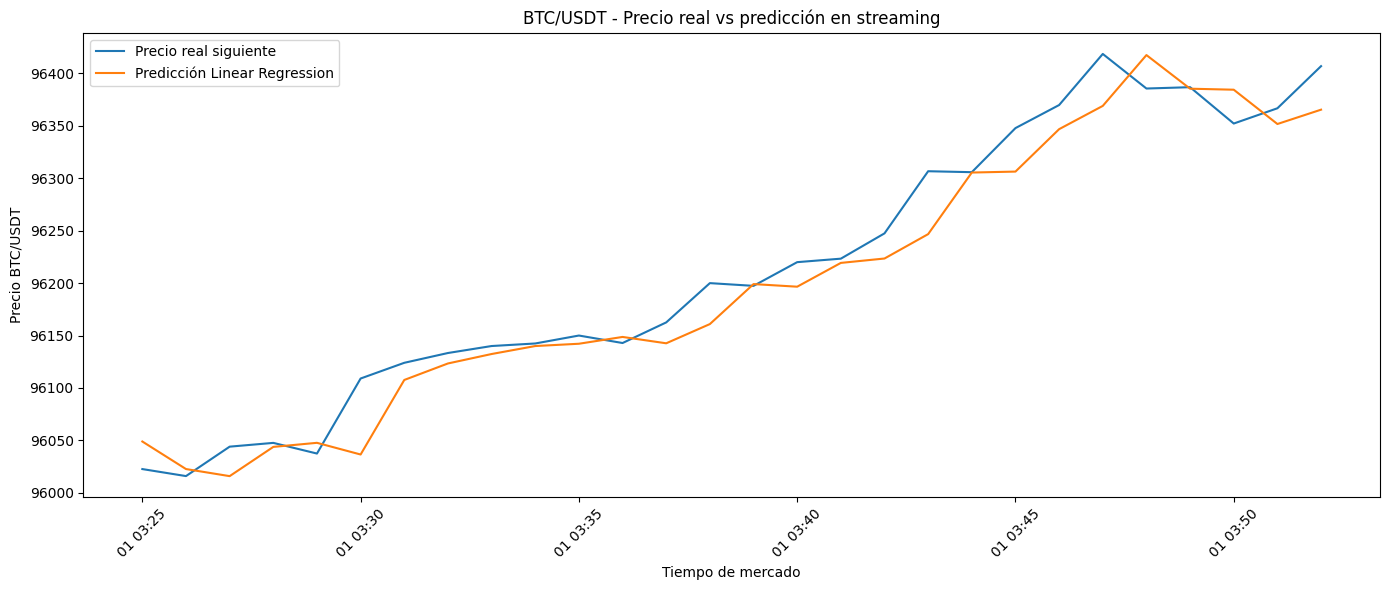

In [101]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    stream_pd["fechaMercado"],
    stream_pd["closeRealSiguiente"],
    label="Precio real siguiente"
)

plt.plot(
    stream_pd["fechaMercado"],
    stream_pd["prediccionSiguienteClose"],
    label="Predicción Linear Regression"
)

plt.title(
    "BTC/USDT - Precio real vs predicción en streaming"
)

plt.xlabel(
    "Tiempo de mercado"
)

plt.ylabel(
    "Precio BTC/USDT"
)

plt.xticks(rotation=45)

plt.legend()

plt.tight_layout()

plt.show()

## Conclusión de la sesión

En esta sesión se construyó un sistema de series de tiempo e inferencia
en streaming aplicado al mercado de criptomonedas, utilizando Bitcoin
(BTC/USDT) como caso de estudio.

Se procesaron 527,040 registros históricos reales correspondientes al
año 2024 con una frecuencia de un minuto. A partir de estos datos se
construyó la variable objetivo mediante `lead(close, 1)`, permitiendo
predecir el precio de cierre del siguiente minuto.

La división entre entrenamiento y prueba se realizó de manera
cronológica para evitar fuga de información temporal.

El baseline de persistencia obtuvo un RMSE de 66.298128, mientras que
Linear Regression obtuvo un RMSE de 66.291428. Por lo tanto, Linear
Regression presentó una mejora de aproximadamente 0.0101 %, siendo el
ganador técnico según RMSE.

Sin embargo, esta mejora fue mínima y el baseline incluso obtuvo un
MAE ligeramente menor. Esto demuestra que una mayor complejidad no
siempre produce una mejora significativa.

Random Forest presentó un rendimiento considerablemente inferior,
evidenciando también que un modelo más complejo no necesariamente es
más adecuado para este tipo de problema temporal.

Finalmente, el modelo Linear Regression fue almacenado como
PipelineModel y utilizado sobre eventos BTC/USDT enviados mediante
Apache Kafka y procesados mediante Spark Structured Streaming,
obteniendo predicciones del precio de cierre del siguiente minuto
sobre eventos recibidos en tiempo real.